In [8]:
# ==============================================================================
# PROJETO: MODELAGEM E PREDIÇÃO DA QUALIDADE DO VINHO TINTO (WINE QUALITY)
# Estrutura Metodológica: (EDA & Preparação) + (CV & Generalização)
# ==============================================================================

# --- 1. CONFIGURAÇÃO DO AMBIENTE E IMPORTAÇÕES ---
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Configurações estéticas do Pandas e Seaborn
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

AZUL = "#3D8DFF"
CINZA = "#5F6B7A"

print("1. Ambiente configurado com sucesso!")


1. Ambiente configurado com sucesso!


In [9]:
# --- 2. CARREGAMENTO E INSPEÇÃO INICIAL ---
# Carregamento exclusivo do arquivo baixado localmente

ARQUIVO_LOCAL = "data/winequality-red.csv"
if not os.path.exists(ARQUIVO_LOCAL):
    ARQUIVO_LOCAL = "winequality-red.csv"
df_raw = pd.read_csv(ARQUIVO_LOCAL, sep=";")
df = df_raw.copy()

print(f"\nDimensionamento Inicial da Base: {df.shape[0]} linhas e {df.shape[1]} colunas")
print("\nPrimeiros registros da base de vinhos:")
display(df.head(3))

# Diagnóstico Inicial de Ausências e Tipos 
diagnostico_inicial = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "ausentes_%": df.isna().mean().mul(100).round(2),
    "distintos": df.nunique(dropna=False)
})
print("\n--- DIAGNÓSTICO INICIAL DOS DADOS ---")
display(diagnostico_inicial)


Dimensionamento Inicial da Base: 1599 linhas e 12 colunas

Primeiros registros da base de vinhos:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5
1,7.800,0.880,0.000,2.600,0.098,25.000,67.000,0.997,3.200,0.680,9.800,5
2,7.800,0.760,0.040,2.300,0.092,15.000,54.000,0.997,3.260,0.650,9.800,5



--- DIAGNÓSTICO INICIAL DOS DADOS ---


,tipo,ausentes,ausentes_%,distintos
fixed acidity,float64,0,0.000,96
volatile acidity,float64,0,0.000,143
citric acid,float64,0,0.000,80
residual sugar,float64,0,0.000,91
chlorides,float64,0,0.000,153
free sulfur dioxide,float64,0,0.000,60
total sulfur dioxide,float64,0,0.000,144
density,float64,0,0.000,436
pH,float64,0,0.000,89
sulphates,float64,0,0.000,96


In [10]:

# --- 3. LIMPEZA E PREPARAÇÃO DOS DADOS ---
# A. Diagnóstico de Duplicidades
duplicadas_qtd = df.duplicated().sum()
print(f"\nLinhas duplicadas encontradas: {duplicadas_qtd}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Linhas restantes após remoção de duplicatas: {len(df)}")

# B. Verificação de Regras de Domínio (pH, Álcool e Qualidade devem ser positivos)
assert (df["pH"] > 0).all(), "Há valores de pH inválidos."
assert (df["alcohol"] > 0).all(), "Há valores de teor alcoólico inválidos."
assert (df["quality"] > 0).all(), "Há valores de qualidade inválidos."
print("Regras de domínio físico-químico verificadas com sucesso.")

# C. Registro Didático das Decisões de Preparação
registro_decisoes = pd.DataFrame([
    ["winequality-red.csv", "Carregamento via separador ';'", "Formato nativo do dataset baixado", "Preservou os 12 atributos originais"],
    ["duplicidades", f"Removidas {duplicadas_qtd} observações idênticas", "Evitar vazamento de dados e sobrepeso na modelagem", f"Amostra mantida em {len(df)} registros"],
    ["quality", "Variável-alvo mantida como numérica contínua/discreta", "Permitir modelagem por regressão linear", "Alvo das predições de qualidade"]
], columns=["variavel", "acao", "justificativa", "impacto_possivel"])

print("\n--- REGISTRO DAS DECISÕES DE PREPARAÇÃO ---")
display(registro_decisoes)



Linhas duplicadas encontradas: 240
Linhas restantes após remoção de duplicatas: 1359
Regras de domínio físico-químico verificadas com sucesso.

--- REGISTRO DAS DECISÕES DE PREPARAÇÃO ---


,variavel,acao,justificativa,impacto_possivel
0,winequality-red.csv,Carregamento via separador ';',Formato nativo do dataset baixado,Preservou os 12 atributos originais
1,duplicidades,Removidas 240 observações idênticas,Evitar vazamento de dados e sobrepeso na model...,Amostra mantida em 1359 registros
2,quality,Variável-alvo mantida como numérica contínua/d...,Permitir modelagem por regressão linear,Alvo das predições de qualidade



--- ANÁLISE EXPLORATÓRIA (UNIVARIADA E BIVARIADA) ---


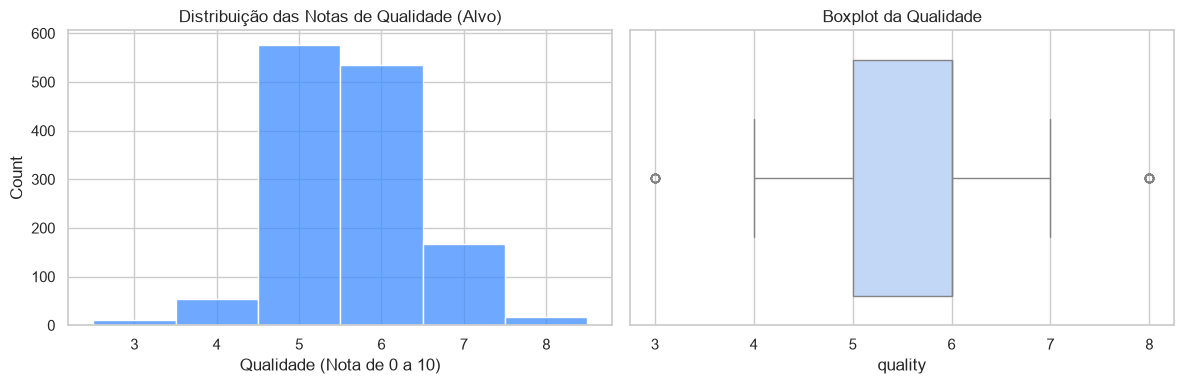


Correlações de Pearson das Variáveis Físico-Químicas com a Qualidade:


,r_Pearson,p_value
alcohol,0.480,0.000
volatile acidity,-0.395,0.000
sulphates,0.249,0.000
citric acid,0.228,0.000
density,-0.184,0.000
total sulfur dioxide,-0.178,0.000
chlorides,-0.131,0.000
fixed acidity,0.119,0.000
pH,-0.055,0.042
free sulfur dioxide,-0.050,0.063


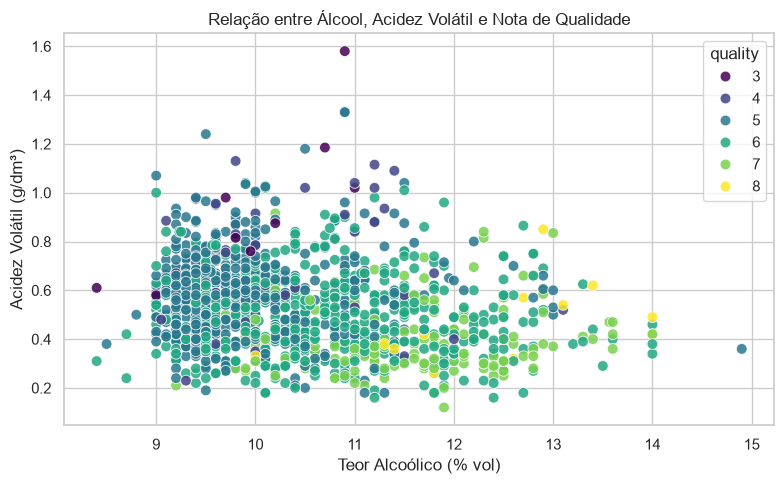

In [11]:

# --- 4. ANÁLISE EXPLORATÓRIA DE DADOS - EDA ---
print("\n--- ANÁLISE EXPLORATÓRIA (UNIVARIADA E BIVARIADA) ---")

# A. Univariada: Distribuição da Variável-Alvo (quality)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["quality"], discrete=True, color=AZUL, ax=axes[0])
axes[0].set_title("Distribuição das Notas de Qualidade (Alvo)")
axes[0].set_xlabel("Qualidade (Nota de 0 a 10)")

sns.boxplot(x=df["quality"], color="#B9D4FF", ax=axes[1])
axes[1].set_title("Boxplot da Qualidade")
plt.tight_layout()
plt.show()

# B. Bivariada: Matriz de Correlação com a Qualidade
correlacoes = df.drop(columns=["quality"]).apply(lambda x: stats.pearsonr(x, df["quality"])[0])
p_values = df.drop(columns=["quality"]).apply(lambda x: stats.pearsonr(x, df["quality"])[1])

df_corr_quality = pd.DataFrame({
    "r_Pearson": correlacoes,
    "p_value": p_values
}).sort_values(by="r_Pearson", key=abs, ascending=False)

print("\nCorrelações de Pearson das Variáveis Físico-Químicas com a Qualidade:")
display(df_corr_quality)

# C. Multivariada: Álcool x Acidez Volátil por Qualidade
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=df, x="alcohol", y="volatile acidity", hue="quality",
    palette="viridis", alpha=0.85, s=60, ax=ax
)
ax.set_title("Relação entre Álcool, Acidez Volátil e Nota de Qualidade")
ax.set_xlabel("Teor Alcoólico (% vol)")
ax.set_ylabel("Acidez Volátil (g/dm³)")
plt.tight_layout()
plt.show()

In [12]:

# --- 5. ISOLAMENTO DO TESTE ("O COFRE") ---
features = [col for col in df.columns if col != "quality"]
X = df[features]
y = df["quality"]

# Divisão: 80% Treino / 20% Teste isolado no "cofre"
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"\nConjunto de Treino: {X_train.shape[0]} amostras")
print(f"Conjunto de Teste (Guardado no Cofre): {X_test.shape[0]} amostras")

# Padronização de escalas (StandardScaler treinado APENAS no treino)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=features)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=features)


Conjunto de Treino: 1087 amostras
Conjunto de Teste (Guardado no Cofre): 272 amostras


In [13]:

# --- 6. VALIDAÇÃO CRUZADA 5-FOLD NO TREINO  ---
kf = KFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    "Regressão Linear Múltipla": LinearRegression(),
    "Regressão Ridge (L2)": Ridge(alpha=10.0)
}

resultados_cv = []

print("\n--- AVALIAÇÃO DE MODELOS VIA VALIDAÇÃO CRUZADA (5-FOLD) NO TREINO ---")
for nome, modelo in modelos.items():
    cv_results = cross_validate(
        modelo,
        X_train_scaled,
        y_train,
        cv=kf,
        scoring={
            'mae': 'neg_mean_absolute_error',
            'rmse': 'neg_root_mean_squared_error',
            'r2': 'r2'
        }
    )

    mae_medio = -cv_results['test_mae'].mean()
    mae_std = cv_results['test_mae'].std()
    rmse_medio = -cv_results['test_rmse'].mean()
    r2_medio = cv_results['test_r2'].mean()

    resultados_cv.append({
        "Modelo": nome,
        "MAE Médio": mae_medio,
        "Desvio Padrão MAE": mae_std,
        "RMSE Médio": rmse_medio,
        "R² Médio": r2_medio
    })

df_cv = pd.DataFrame(resultados_cv).sort_values("MAE Médio")
display(df_cv)


--- AVALIAÇÃO DE MODELOS VIA VALIDAÇÃO CRUZADA (5-FOLD) NO TREINO ---


,Modelo,MAE Médio,Desvio Padrão MAE,RMSE Médio,R² Médio
1,Regressão Ridge (L2),0.517,0.018,0.668,0.322
0,Regressão Linear Múltipla,0.518,0.018,0.668,0.321


In [14]:

# --- 7. SELEÇÃO, REAJUSTE E MEDIÇÃO DE GENERALIZAÇÃO NO TESTE ---
# Selecionando o campeão pelo menor MAE médio na Validação Cruzada
modelo_campeao_nome = df_cv.iloc[0]["Modelo"]
modelo_campeao = modelos[modelo_campeao_nome]

print(f"\nModelo Campeão Selecionado: {modelo_campeao_nome}")

# REAJUSTE (FIT) COM 100% DOS DADOS DE TREINO
modelo_campeao.fit(X_train_scaled, y_train)

# ABRINDO O COFRE: Predição e avaliação no conjunto de TESTE
y_pred_test = modelo_campeao.predict(X_test_scaled)

mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print("\n==========================================================")
print("  DESEMPENHO FINAL DE GENERALIZAÇÃO (CONJUNTO DE TESTE)  ")
print("==========================================================")
print(f"MAE  no Teste: {mae_test:.4f}")
print(f"RMSE no Teste: {rmse_test:.4f}")
print(f"R²   no Teste: {r2_test:.4f}")


Modelo Campeão Selecionado: Regressão Ridge (L2)

  DESEMPENHO FINAL DE GENERALIZAÇÃO (CONJUNTO DE TESTE)  
MAE  no Teste: 0.5038
RMSE no Teste: 0.6554
R²   no Teste: 0.3936


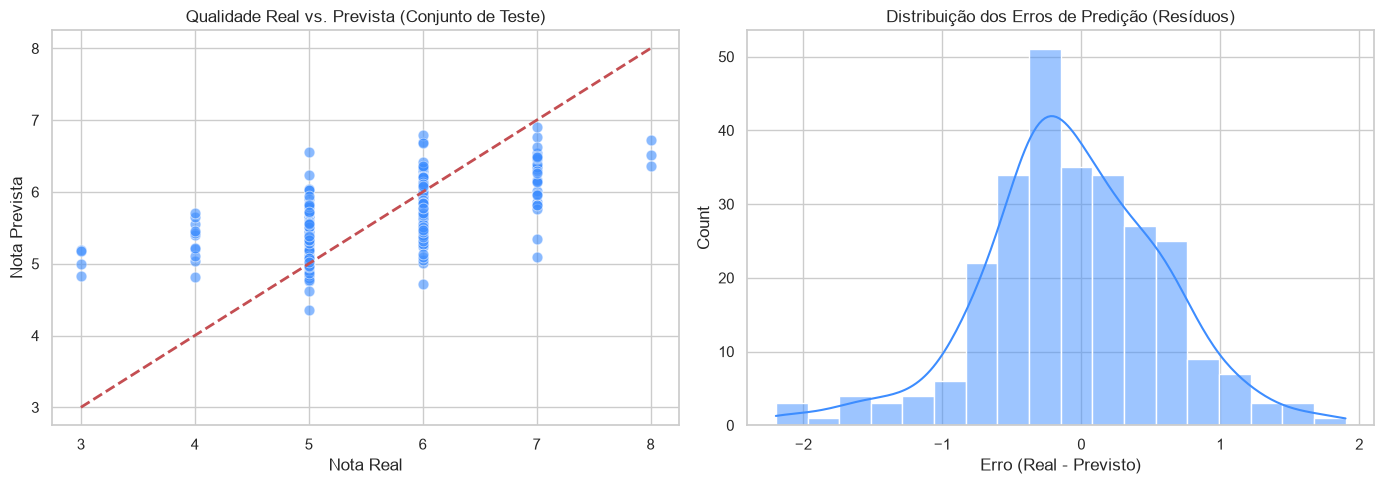


Top 5 Maiores Desvios de Predição do Modelo no Teste:


,Qualidade Real,Qualidade Prevista,Erro Absoluto,Resíduo
96,3,5.198,2.198,-2.198
182,3,5.177,2.177,-2.177
224,3,4.994,1.994,-1.994
238,7,5.099,1.901,1.901
135,3,4.823,1.823,-1.823


In [15]:
# --- 8. ANÁLISE DE RESÍDUOS E DIAGNÓSTICO DOS MAIORES ERROS ---
df_residuos = pd.DataFrame({
    "Qualidade Real": y_test.values,
    "Qualidade Prevista": y_pred_test,
    "Erro Absoluto": np.abs(y_test.values - y_pred_test),
    "Resíduo": y_test.values - y_pred_test
}).sort_values("Erro Absoluto", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Real vs Previsto
sns.scatterplot(x=y_test, y=y_pred_test, alpha=0.6, color=AZUL, s=60, ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title("Qualidade Real vs. Prevista (Conjunto de Teste)")
axes[0].set_xlabel("Nota Real")
axes[0].set_ylabel("Nota Prevista")

# Gráfico 2: Distribuição dos Resíduos
sns.histplot(df_residuos["Resíduo"], kde=True, color=AZUL, ax=axes[1])
axes[1].set_title("Distribuição dos Erros de Predição (Resíduos)")
axes[1].set_xlabel("Erro (Real - Previsto)")

plt.tight_layout()
plt.show()

print("\nTop 5 Maiores Desvios de Predição do Modelo no Teste:")
display(df_residuos.head())